In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv('/Users/udaykumarreddy/Desktop/Advanced Data Science Technique/Linear Regression/playgolf_data.csv')

df.head()

,Outlook,Temperature,Humidity,Wind,PlayGolf
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rainy,Mild,High,Weak,Yes
4,Rainy,Cool,Normal,Weak,Yes


In [3]:
df

,Outlook,Temperature,Humidity,Wind,PlayGolf
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rainy,Mild,High,Weak,Yes
4,Rainy,Cool,Normal,Weak,Yes
5,Rainy,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rainy,Mild,Normal,Weak,Yes


In [4]:
df.shape

(14, 5)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Outlook      14 non-null     str  
 1   Temperature  14 non-null     str  
 2   Humidity     14 non-null     str  
 3   Wind         14 non-null     str  
 4   PlayGolf     14 non-null     str  
dtypes: str(5)
memory usage: 1001.0 bytes


In [6]:
df.describe(include="all")

,Outlook,Temperature,Humidity,Wind,PlayGolf
count,14,14,14,14,14
unique,3,3,2,2,2
top,Sunny,Mild,High,Weak,Yes
freq,5,6,7,8,9


In [7]:
print(df.isnull().sum())

Outlook        0
Temperature    0
Humidity       0
Wind           0
PlayGolf       0
dtype: int64


In [8]:
print(df.duplicated().sum())

0


In [9]:
numerical_variables = df.select_dtypes(include=["number"]).columns
categorical_variables = df.select_dtypes(include=["object", "category", "str"]).columns

print("Numerical Variables:")
print(list(numerical_variables))

print("\nCategorical Variables:")
print(list(categorical_variables))

Numerical Variables:
[]

Categorical Variables:
['Outlook', 'Temperature', 'Humidity', 'Wind', 'PlayGolf']


In [10]:
print("Target Variable: PlayGolf")

Target Variable: PlayGolf


In [11]:
df = df.drop_duplicates().copy()

print("Dataset Shape:", df.shape)

Dataset Shape: (14, 5)


In [12]:
df = df.dropna().copy()

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Outlook        0
Temperature    0
Humidity       0
Wind           0
PlayGolf       0
dtype: int64


In [13]:
le = LabelEncoder()

for column in df.columns:
    df[column] = le.fit_transform(df[column])

df.head()

,Outlook,Temperature,Humidity,Wind,PlayGolf
0,2,1,0,1,0
1,2,1,0,0,0
2,0,1,0,1,1
3,1,2,0,1,1
4,1,0,1,1,1


In [14]:
X = df.drop(columns=["PlayGolf"])

y = df["PlayGolf"]

print("Independent Variables:")
print(X.columns.tolist())

print("\nDependent Variable:")
print(y.name)

Independent Variables:
['Outlook', 'Temperature', 'Humidity', 'Wind']

Dependent Variable:
PlayGolf


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [16]:
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (11, 4)
Testing Data: (3, 4)


In [17]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [18]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.tolist())

print("\nPredicted Values:")
print(y_pred.tolist())

Actual Values:
[0, 1, 1]

Predicted Values:
[1, 1, 1]


In [19]:
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:", round(accuracy * 100, 2), "%")

Random Forest Accuracy: 66.67 %


In [20]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

       Feature  Importance
0      Outlook    0.394225
3         Wind    0.284514
1  Temperature    0.174036
2     Humidity    0.147225


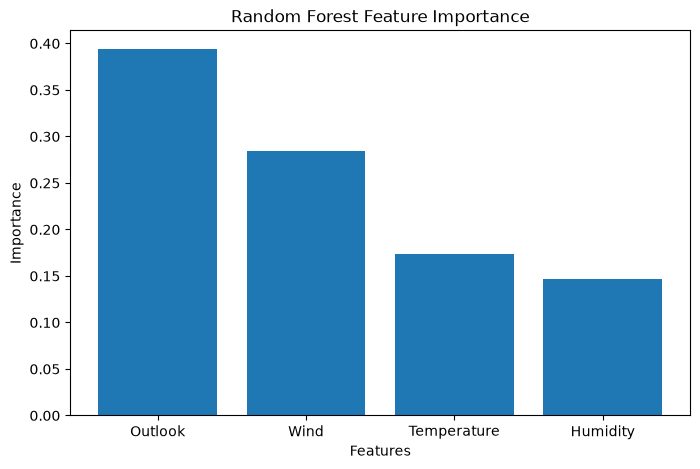

In [21]:
plt.figure(figsize=(8, 5))

plt.bar(importance["Feature"], importance["Importance"])

plt.title("Random Forest Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.show()